In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from src.data.data_manager import create_data_loaders, create_file_based_splits
from src.utils.config_manager import load_config
from src.utils.baselines.feature_extraction import extract_features_from_indices
from src.utils.baselines.ridge_elasticnet_regression import (
    train_ridge_regression,
    train_elasticnet_regression,
    evaluate_models,
    plot_predictions
)

In [2]:
plt.rcParams['figure.figsize'] = (12, 6)

config = load_config()
mode = config['model'].get('type', 'regression')

print(f"Configuration:")
print(f"  - Sample rate: {config['data']['sample_rate']}")
print(f"  - Slice length: {config['data']['slice_length']}s")
print(f"  - Test split: {config['data']['test_split']}")
print(f"  - Val split: {config['data']['val_split']}")

train_loader, val_loader, test_loader, dataset = create_data_loaders(config)

print(f"\nSet sizes:")
print(f"  - Train: {len(train_loader.dataset)} samples")
print(f"  - Val: {len(val_loader.dataset)} samples")
print(f"  - Test: {len(test_loader.dataset)} samples")

Configuration:
  - Sample rate: 48000
  - Slice length: 0.1s
  - Test split: 0.2
  - Val split: 0.2
Total samples: 1975
Total unique audio files: 333
Split results:
  Train files: 212 -> 1261 slices
  Val files: 54 -> 329 slices
  Test files: 67 -> 385 slices

Set sizes:
  - Train: 1261 samples
  - Val: 329 samples
  - Test: 385 samples


Label shapes:
  - Train: (1261,)
  - Val: (329,)
  - Test: (385,)

Statistics (train):
  - Min: 29.00°C
  - Max: 45.00°C
  - Mean: 37.22°C
  - Median: 37.50°C
  - Std: 4.57°C


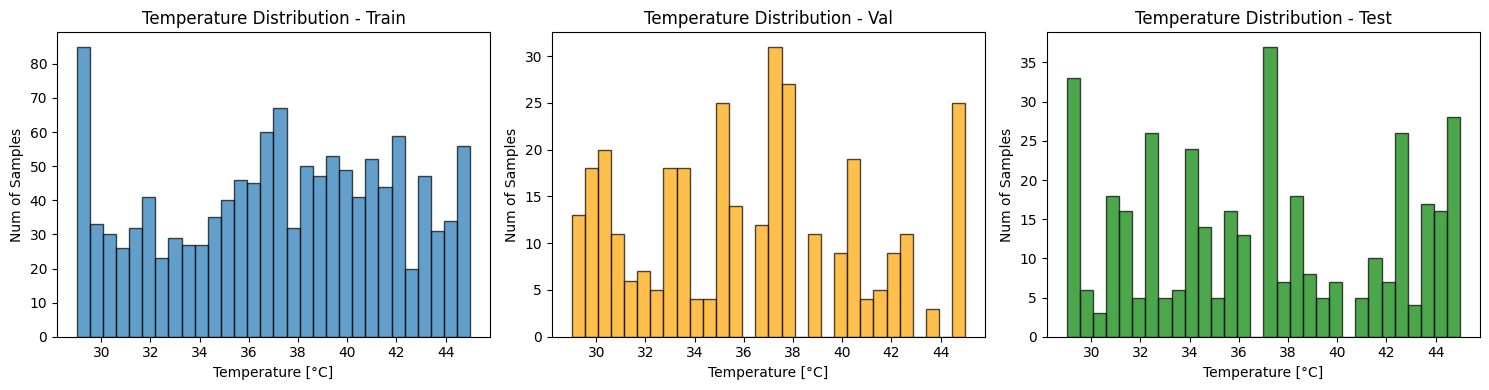

In [3]:
def extract_labels(data_loader):
    labels = []
    for _, label in data_loader:
        if isinstance(label, torch.Tensor):
            labels.extend(label.cpu().numpy())
        else:
            labels.extend(label)
    return np.array(labels)

y_train = extract_labels(train_loader)
y_val = extract_labels(val_loader)
y_test = extract_labels(test_loader)

print("Label shapes:")
print(f"  - Train: {y_train.shape}")
print(f"  - Val: {y_val.shape}")
print(f"  - Test: {y_test.shape}")

y_train = y_train.flatten()
y_val = y_val.flatten()
y_test = y_test.flatten()
print(f"\nStatistics (train):")
print(f"  - Min: {y_train.min():.2f}°C")
print(f"  - Max: {y_train.max():.2f}°C")
print(f"  - Mean: {y_train.mean():.2f}°C")
print(f"  - Median: {np.median(y_train):.2f}°C")
print(f"  - Std: {y_train.std():.2f}°C")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(y_train, bins=30, alpha=0.7, edgecolor='black')
axes[0].set_title('Temperature Distribution - Train')
axes[0].set_xlabel('Temperature [°C]')
axes[0].set_ylabel('Num of Samples')
axes[1].hist(y_val, bins=30, alpha=0.7, edgecolor='black', color='orange')
axes[1].set_title('Temperature Distribution - Val')
axes[1].set_xlabel('Temperature [°C]')
axes[1].set_ylabel('Num of Samples')
axes[2].hist(y_test, bins=30, alpha=0.7, edgecolor='black', color='green')
axes[2].set_title('Temperature Distribution - Test')
axes[2].set_xlabel('Temperature [°C]')
axes[2].set_ylabel('Num of Samples')

plt.tight_layout()
plt.savefig('../../results/baselines/data_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
train_indices, val_indices, test_indices = create_file_based_splits(
    dataset,
    test_split=config['data']['test_split'],
    val_split=config['data']['val_split'],
    random_seed=config['data']['random_seed']
)

X_train, y_train, groups_train = extract_features_from_indices(dataset, train_indices)
X_val, y_val, groups_val = extract_features_from_indices(dataset, val_indices)
X_test, y_test, groups_test = extract_features_from_indices(dataset, test_indices)

X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)
X_val = np.nan_to_num(X_val, nan=0.0, posinf=0.0, neginf=0.0)
X_test = np.nan_to_num(X_test, nan=0.0, posinf=0.0, neginf=0.0)

print("FEATURE EXTRACTION")
print(f"\nShape of features:")
print(f"  - X_train: {X_train.shape}")
print(f"  - X_val: {X_val.shape}")
print(f"  - X_test: {X_test.shape}")
print(f"  - Number of features: {X_train.shape[1]}")

Total unique audio files: 333
Split results:
  Train files: 212 -> 154 slices
  Val files: 54 -> 329 slices
  Test files: 67 -> 385 slices
FEATURE EXTRACTION

Shape of features:
  - X_train: (154, 51)
  - X_val: (329, 51)
  - X_test: (385, 51)
  - Number of features: 51


## Ridge and ElasticNet Regression

### TODO add scaling

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Ridge - Best params: {'alpha': 1.0}, CV R²: -2.2706
Fitting 5 folds for each of 25 candidates, totalling 125 fits


C:\Users\Ania\PycharmProjects\vibro-ml-v1\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.294e+03, tolerance: 5.172e-01
  model = cd_fast.enet_coordinate_descent(


ElasticNet - Best params: {'alpha': 0.1, 'l1_ratio': 0.3}, CV R²: 0.1211
        Model        R2      RMSE       MAE
0       Ridge -0.282373  5.129225  3.991622
1  ElasticNet -0.150724  4.858814  3.783674


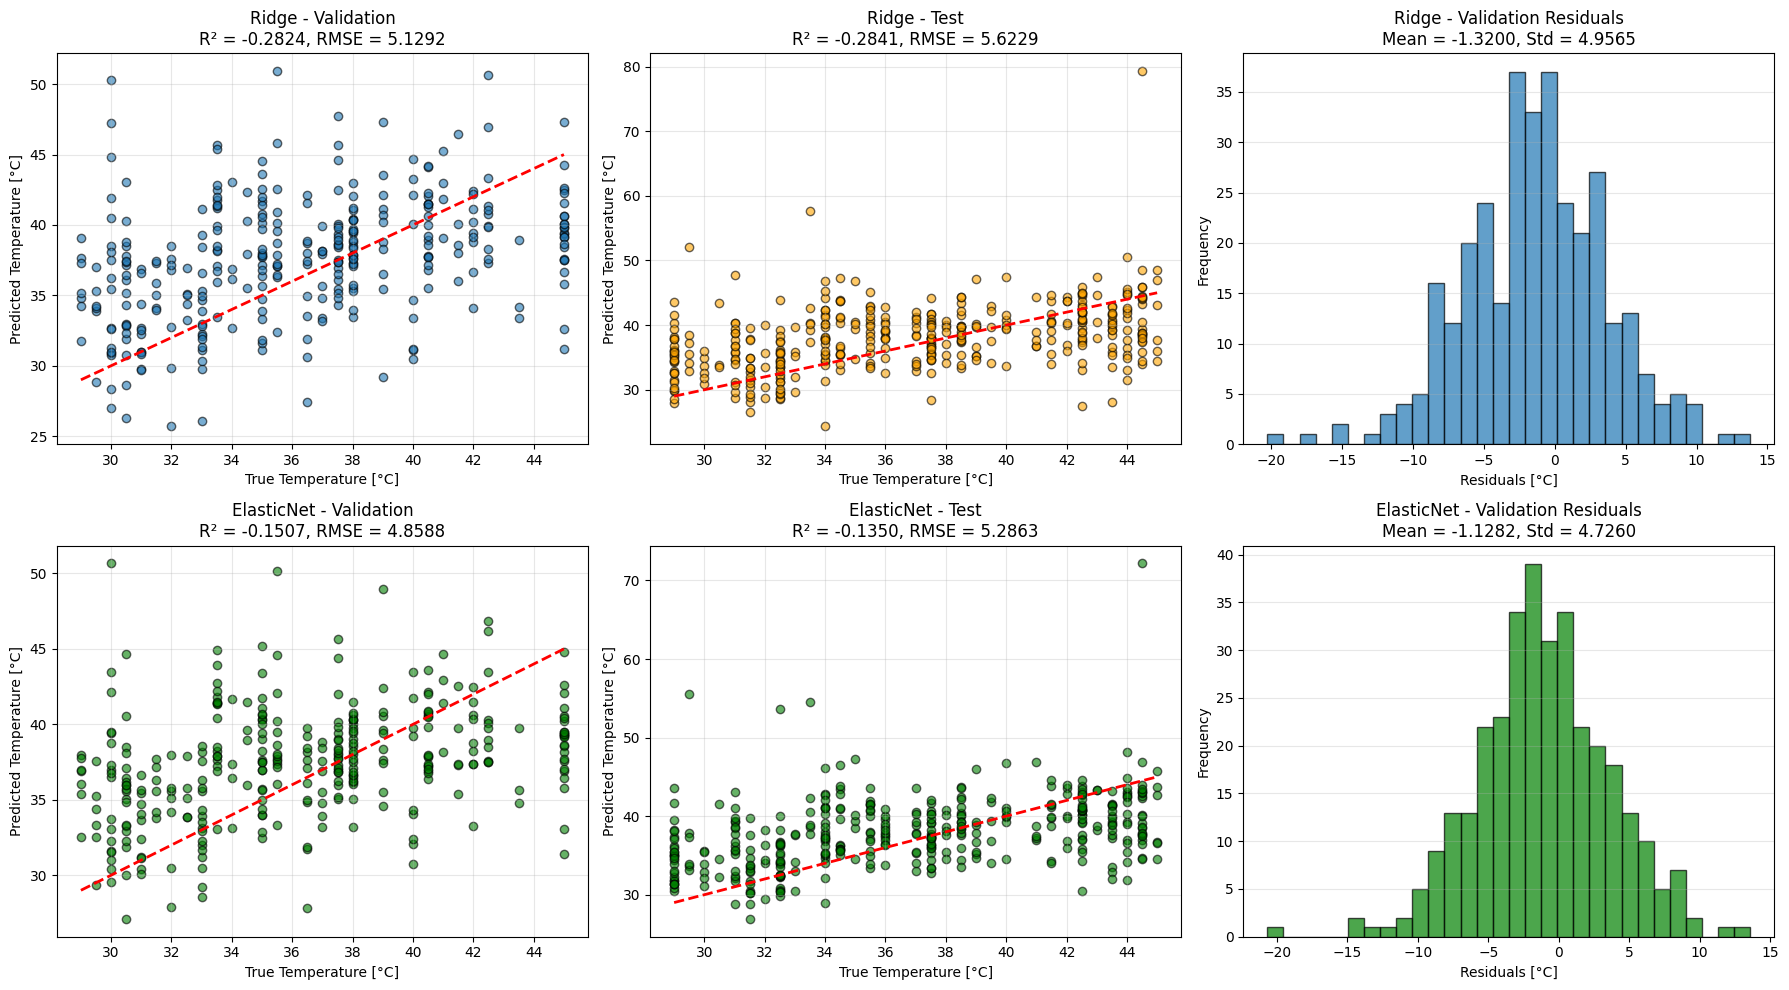

In [5]:
X_train, y_train, groups_train = extract_features_from_indices(dataset, train_indices)
X_val, y_val, groups_val = extract_features_from_indices(dataset, val_indices)
X_test, y_test, groups_test = extract_features_from_indices(dataset, test_indices)

ridge_model, ridge_params, ridge_cv_score = train_ridge_regression(
    X_train, y_train, groups_train=groups_train
)
print(f"Ridge - Best params: {ridge_params}, CV R²: {ridge_cv_score:.4f}")

elasticnet_model, elasticnet_params, elasticnet_cv_score = train_elasticnet_regression(
    X_train, y_train, groups_train=groups_train
)
print(f"ElasticNet - Best params: {elasticnet_params}, CV R²: {elasticnet_cv_score:.4f}")

y_pred_ridge_val = ridge_model.predict(X_val)
y_pred_ridge_test = ridge_model.predict(X_test)
y_pred_elasticnet_val = elasticnet_model.predict(X_val)
y_pred_elasticnet_test = elasticnet_model.predict(X_test)

results_df = evaluate_models(y_val, y_pred_ridge_val, y_pred_elasticnet_val)
print(results_df)
fig = plot_predictions(
    y_val, y_pred_ridge_val, y_test, y_pred_ridge_test,
    y_pred_elasticnet_val, y_pred_elasticnet_test
)
plt.show()